# Harvest cycles: can a pixel's cut-and-regrow history tell plantations from natural forest?

Plantations in Paraná, Santa Catarina and Rio Grande do Sul are clear-cut and replanted in rotations; natural forest is not. This notebook tests whether each pixel's own Landsat history from 1985 to 2020 tells the two apart, using only imagery up to the cutoff date of the EU Deforestation Regulation (EUDR), 31 December 2020. It starts from the yearly Landsat values and computes every result below itself.

## Findings at a glance

| | MapBiomas reference points | Cropin QC clearings (independent test) |
|---|---|---|
| Plantations vs natural forest with a detected clear-cut before 2021 | 76% vs 14% | 35% vs 20% |
| … with at least one cut-and-regrow cycle (clustered p) | 72% vs 14% (p = 3 × 10⁻⁹⁸) | 34% vs 19% (p = 0.006) |
| … with an abrupt start on open land | 45% vs 1.1% | 14% vs 4.1% |
| How much NBR varied over 1985–2020, one number (AUC; picked after first results) | 0.97 | 0.76 |
| All ten harvest features in a model (AUC) | 0.945–0.947 | 0.74–0.76 |
| The 36 yearly values in a random forest (AUC) | 0.973 | 0.81 |
| Hansen's loss/gain record alone, for comparison (AUC) | 0.92–0.93 | 0.68–0.70 |
| “Forest every year since 1985”: forest protected / plantations wrongly vetoed | 45% / 1.6% | 30% / 6.1% |

**Terms.** *NBR* (normalised burn ratio): a Landsat index, high under closed canopy, that drops sharply at a clear-cut. *Cut*: an NBR fall of at least 0.20 within 3 years. *Cycle*: a cut that grows back half the fall within 10 years. *Abrupt start*: at least 3 years at open-land NBR, then closed canopy within 5 years. *AUC*: the chance that a random plantation scores higher than a random natural forest (0.5 = coin flip, 1.0 = perfect). *Clustered p*: a p-value that allows nearby points to be alike. *QC clearings*: Cropin's hand-checked quality-control set; models never see them in training. *Forest protected / plantations wrongly vetoed*: the shares of natural forest and of plantations that pass “forest every year since 1985”, which would cancel a plantation call.

1. **Yes on the MapBiomas points, partly on Cropin's clearings.** On the MapBiomas points every harvest feature except regrowth speed separates plantation from forest. On Cropin's clearings the gaps are much smaller, and “two or more cycles” is no longer significant.
2. **The harvest history alone beats the team's current features** on the MapBiomas points (0.945–0.947 vs 0.909–0.919), using only data up to 2020. Hansen's free loss/gain record does almost as well there but transfers worse to Cropin's clearings; together they reach 0.96 and 0.77.
3. **Use summaries of the whole series, not counts of cycles.** NBR variability separates far better than the number of cuts (+0.13 AUC on MapBiomas points, +0.19 on QC). It was singled out after the first results, so confirm it on new data.
4. **Regrowth speed does not separate**, likely because NBR comes back within about two years under any woody regrowth.
5. **Cropin's clearings are harder.** They are small (plantation clearings show a cut 33–36% of the time at any size up to 2,700 m², 64% only above), few were cut in 2010–2020, and their forest fails “forest since 1985” more often (70% vs 55%).
6. **“Forest every year since 1985” works as a veto, at a cost**: it protects 45% of natural forest and wrongly cancels 1.6% of plantations on the MapBiomas points, but 30% and 6.1% on Cropin's clearings. Use it only to cancel a plantation call, never to make one.
7. **For reference**, adding the harvest history to the team's features lifts their model from 0.91–0.92 to 0.97, and it then finds as many plantations as the MapBiomas 10 m map at about the same false-alarm rate (88% vs 86%). Those combined models use 2022 imagery.
8. **Against Cropin's own tools (stand-ins, MapBiomas points):** inside an approximate version of Cropin's forest layer the harvest history flags about 3% of natural forest (5.7–6.5% of Cropin's QC forest clearings); added to the team's SAG values, it catches 87% of plantations instead of 45% (harvest history alone: 78%). That combination uses 2022 imagery.
9. MapBiomas-point results are an **upper bound**: MapBiomas interpreters label those points from the same Landsat archive.

## How to run

- **Inputs.** Everything except Cropin's labels is in the repository, in `public_data/harvest_cycles/`: the point table, yearly Landsat NBR/NDVI series, Hansen values and Meta canopy height at every point (see its README for how they were made), plus the team's `data_exploration/cropin_model_features_2022.csv`. Cropin's labels are confidential and are read from their GeoJSON in `CROPIN-MIT-DATA/cropin_qc_data/` (git-ignored), which the team already has. Nothing is downloaded.
- **Everything else** is computed here, top to bottom, in about 8 minutes on 4 CPUs. The notebook needs no other code from the repository.
- **Environment.** Run it from anywhere in the repository. It needs numpy, pandas, scipy, matplotlib, statsmodels and scikit-learn ≥ 1.6 (for `GroupKFold(shuffle=True)`). The outputs shown were produced with Python 3.13, scikit-learn 1.9, pandas 3.0 and statsmodels 0.15.
- **Confidentiality.** Cropin's QC labels are confidential: they stay in the git-ignored GeoJSON, and this notebook only shows totals, rates and model scores for the QC clearings, never a single clearing.

In [1]:
import json
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

INPUTS = ["points.csv", "hansen_gfc.csv", "val_label_history.csv", "canopy_height.csv"] + [
    f"series_{name}.csv.gz" for name in ["nbr_median", "ndvi_median", "nbr_dry_median", "nbr_wet_median", "nbr_max"]]


def find_up(rel):
    # `rel` in the current folder or the nearest parent folder that has it (the notebook runs from anywhere in the repository)
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / rel).exists():
            return d / rel
    return Path(rel)


DATA = find_up("public_data/harvest_cycles")                  # Landsat and Hansen values at every point (in the repository)
QC_LABELS = find_up("CROPIN-MIT-DATA/cropin_qc_data")         # Cropin's labels: confidential, never on GitHub
TEAM_TABLE = find_up("data_exploration/cropin_model_features_2022.csv")
missing = [str(DATA / f) for f in INPUTS if not (DATA / f).exists()] + [str(p) for p in [TEAM_TABLE] if not p.exists()]
if not list(QC_LABELS.glob("*.geojson")):
    missing.append(f"{QC_LABELS}/*.geojson (Cropin's QC file)")
if missing:
    raise FileNotFoundError("Not found: " + ", ".join(missing) + ". See 'How to run'.")

YEARS = np.arange(1985, 2021)        # 36 years, up to the EUDR cutoff
SEED = 42
PLANT, FOREST, CUT, GREY = "#c8800d", "#197037", "#b8358a", "#7d8a83"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e3e8e4", "font.size": 10, "legend.frameon": False})


def pct(x):
    return "–" if pd.isna(x) else (f"{100 * x:.1f}%" if 0 < x < 0.1 else f"{100 * x:.0f}%")


def num(x):
    # two significant digits, without scientific notation for ordinary sizes
    return f"{x:.0f}" if x >= 10 else (f"{x:.1f}" if x >= 1 else f"{x:.2g}")


def pval(p):
    return "–" if pd.isna(p) else f"{p:.2g}"

## 1. The data

Two sets of points, each read as **one Landsat pixel**:

- **MapBiomas reference points**: the 1,831 points of the team's model table, labelled plantation or natural forest by MapBiomas interpreters (2022 reference). Used for training and for the first results.
- **Cropin QC clearings**: 433 clearings that Cropin checked by hand. 310 were plantation harvests reported as deforestation (false alarms) and 123 were real clearing of natural forest. Their labels are never used for training: they are the independent test.

**The costly error** is calling natural forest a plantation, because that would hide real deforestation. Models are therefore compared at a threshold that flags at most 5% of natural forest as plantation (the MapBiomas 10 m map flags 5.1%), and the veto in section 5 may only cancel plantation calls.

**Yearly NBR.** For every point there is one NBR value per year, 1985–2020: the median of all clear observations from Landsat 4, 5, 7 and 8 (Collection 1, top-of-atmosphere reflectance; a median of 6 clear observations per point and year, with Landsat 4, 5 and 8 shifted onto the Landsat 7 scale). NBR = (NIR − SWIR2) / (NIR + SWIR2), from the near-infrared and shortwave-infrared 2 bands.

These yearly values were downloaded once from Google's public Landsat archive and are stored in `public_data/harvest_cycles/`.

**Hansen Global Forest Change** gives each pixel's tree cover in 2000, forest gain 2000–2012 and forest-loss year; losses after 2020 are ignored. It sets the two NBR levels in section 2 and is shown for comparison throughout.

In [2]:
pts = pd.read_csv(DATA / "points.csv")              # dataset: val (MapBiomas) or qc (Cropin); label: 1 = plantation

# Cropin's labels are not in the repository: read them from their GeoJSON, whose polygons are in the order Q000, Q001, ...
features = json.load(open(next(QC_LABELS.glob("*.geojson"))))["features"]
qc_rows = pts.index[pts.dataset == "qc"]
assert len(features) == len(qc_rows), "the QC GeoJSON does not match public_data/harvest_cycles/points.csv"


def corners(c):                                     # every (lon, lat) of a polygon or multipolygon
    return [c[:2]] if isinstance(c[0], (int, float)) else [p for part in c for p in corners(part)]


for row, f in zip(qc_rows, features):               # each point must lie inside its own polygon's bounding box
    xy, p = np.array(corners(f["geometry"]["coordinates"])), pts.loc[row, ["lon", "lat"]].to_numpy(float)
    assert (xy.min(0) <= p).all() and (p <= xy.max(0)).all(), "the QC GeoJSON is not in the expected order"
pts.loc[qc_rows, "label"] = [int(f["properties"]["qc_label"] == "plantation") for f in features]
pts["label"] = pts["label"].astype(int)


def read_series(name):
    s = pd.read_csv(DATA / f"series_{name}.csv.gz", index_col=0).reindex(pts["pid"])
    s.columns = s.columns.astype(int)
    return s                                        # one row per point, one column per year 1985..2020


nbr = read_series("nbr_median")
hansen = pd.read_csv(DATA / "hansen_gfc.csv")        # Hansen Global Forest Change: tree cover 2000, gain, loss year
history = pd.read_csv(DATA / "val_label_history.csv")  # MapBiomas reference class per year (MapBiomas points only)
team = pd.read_csv(TEAM_TABLE)                      # the team's features and MapBiomas 10 m map calls
team["ever_farm"] = (team["ever_farm_mean"] >= 0.5).astype(int)

counts = pd.crosstab(pts["dataset"].map({"val": "MapBiomas reference points", "qc": "Cropin QC clearings"}),
                     pts["label"].map({1: "plantation", 0: "natural forest"}))
counts["total"] = counts.sum(axis=1)
print(f"Yearly NBR values per point: {nbr.shape[1]} ({YEARS[0]}–{YEARS[-1]}); missing point-years: {nbr.isna().mean().mean():.1%}")
print(f"Cropin clearings: median area {pts.loc[pts.dataset == 'qc', 'qc_area_m2'].median():.0f} m² (one Landsat pixel is 900 m²)")
counts

Yearly NBR values per point: 36 (1985–2020); missing point-years: 0.4%
Cropin clearings: median area 269 m² (one Landsat pixel is 900 m²)


label,natural forest,plantation,total
dataset,,,
Cropin QC clearings,123,310,433
MapBiomas reference points,1402,429,1831


## 2. Reading a pixel

Closed canopy typically sits near NBR 0.7; a clear-cut pulls it down sharply and it climbs back as trees regrow.

**Two levels, set from Hansen tree cover at our own points (MapBiomas and QC alike), never from the labels:**
- *Closed canopy*: the 5th percentile of 2000–2020 NBR at pixels with ≥ 90% tree cover in 2000, no Hansen gain, and no Hansen loss up to 2020 in the pixel or its neighbours. It is a floor: 95% of yearly values at such stable pixels lie above it.
- *Open land*: the 25th percentile of 1999–2001 NBR at pixels with ≤ 10% tree cover in 2000 and no gain (capped at half a cut below closed canopy).

In [3]:
def levels(series, drop):
    # closed-canopy and open-land levels of a yearly series, from Hansen tree cover only
    closed = hansen[(hansen.tc2000 >= 90) & ~hansen.lossyear.between(1, 20) & (hansen.gain == 0)
                    & (hansen.loss_3x3_le2020_n == 0)].pid
    open_land = hansen[(hansen.tc2000 <= 10) & (hansen.gain == 0)].pid
    v_closed = series.loc[series.index.isin(closed), [y for y in YEARS if y >= 2000]].to_numpy().ravel()
    v_open = series.loc[series.index.isin(open_land), [1999, 2000, 2001]].to_numpy().ravel()
    canopy = np.percentile(v_closed[np.isfinite(v_closed)], 5)
    return canopy, min(np.percentile(v_open[np.isfinite(v_open)], 25), canopy - drop / 2), len(closed), len(open_land)


CANOPY, OPEN, n_closed, n_open = levels(nbr, drop=0.20)
print(f"Closed-canopy level (5th percentile at stable closed-canopy pixels): NBR {CANOPY:.3f}  (from {n_closed:,} pixels)")
print(f"Open-land level (25th percentile at open-land pixels):              NBR {OPEN:.3f}  (from {n_open} pixels)")

Closed-canopy level (5th percentile at stable closed-canopy pixels): NBR 0.584  (from 1,342 pixels)
Open-land level (25th percentile at open-land pixels):              NBR 0.405  (from 79 pixels)


**From a yearly series to harvest events.** For each pixel, on its own:

1. Remove one-year spikes (a value far from both of its neighbours, which agree with each other).
2. Fit straight-line segments through the yearly values, LandTrendr-style: up to 18 segments, the number chosen by BIC. LandTrendr's usual cap of 6 leaves room for only about two cuts.
3. A **cut** is a fall of at least **0.20 NBR within at most 3 years** between two segment ends. A **cycle** is a cut that grows back **half of the fall within 10 years**.

Nothing here assumes plantations are cut in the same years: each pixel's cuts are found wherever they fall.

In [4]:
DROP, MAX_CUT_YEARS, MAX_REGROW_YEARS = 0.20, 3, 10


def despike(y, thr=0.9, min_spike=0.05):
    # replace one-year spikes by the mean of their two neighbours, largest first
    y = np.asarray(y, float).copy()
    if len(y) < 3:
        return y
    for _ in range(len(y)):
        mid = (y[:-2] + y[2:]) / 2
        s = y[1:-1] - mid
        spike = (np.abs(s) >= min_spike) & (np.abs(y[2:] - y[:-2]) < (1 - thr) * np.abs(s))
        if not spike.any():
            break
        k = int(np.argmax(np.where(spike, np.abs(s), -1)))
        y[k + 1] = mid[k]
    return y


def segment(t, y, max_segments=18):
    # best straight-line fit through yearly points for 1..max_segments segments; keep the one with the lowest BIC
    y = despike(y)
    n = len(t)
    if n < 6:
        return t[[0, -1]], y[[0, -1]], np.interp(t, t[[0, -1]], y[[0, -1]])
    cost = np.zeros((n, n))                         # error of one straight line from year i to year j
    for i in range(n - 1):
        for j in range(i + 1, n):
            line = y[i] + (y[j] - y[i]) * (t[i:j + 1] - t[i]) / (t[j] - t[i])
            cost[i, j] = np.sum((y[i:j + 1] - line) ** 2)
    kmax = min(max_segments, n - 2)
    best_cost = np.full((kmax + 1, n), np.inf)
    back = np.full((kmax + 1, n), -1)
    best_cost[0, 0] = 0.0
    for k in range(1, kmax + 1):                     # dynamic programming over segment ends
        for j in range(1, n):
            cand = best_cost[k - 1, :j] + cost[:j, j]
            i = int(np.argmin(cand))
            best_cost[k, j], back[k, j] = cand[i], i
    best = None
    for k in range(1, kmax + 1):
        if not np.isfinite(best_cost[k, n - 1]):
            continue
        ends, j = [n - 1], n - 1
        for kk in range(k, 0, -1):
            j = back[kk, j]
            ends.append(j)
        ends = sorted(ends)
        basis = np.column_stack([np.interp(t, t[ends], np.eye(len(ends))[m]) for m in range(len(ends))])
        values = np.linalg.lstsq(basis, y, rcond=None)[0]      # refit the segment-end values
        fit = basis @ values
        bic = n * np.log(np.sum((y - fit) ** 2) / n + 1e-6) + 2 * k * np.log(n)
        if best is None or bic < best[0]:
            best = (bic, ends, values, fit)
    _, ends, values, fit = best
    return t[ends], values, fit


def time_to_reach(t, fit, start, target):
    # first year >= start at which the fitted line reaches target (linear interpolation), or None
    idx = np.where(t >= start)[0]
    for a, b in zip(idx[:-1], idx[1:]):
        if fit[a] >= target:
            return t[a]
        if fit[b] >= target:
            return t[a] + (target - fit[a]) / (fit[b] - fit[a]) * (t[b] - t[a])
    if len(idx) and fit[idx[-1]] >= target:
        return t[idx[-1]]
    return None


def find_cuts(tv, vv, t, fit, drop=DROP):
    # cuts = falls >= drop between consecutive segment ends at most 3 years apart; cycle = regrows half within 10 years
    events = []
    for t0, t1, v0, v1 in zip(tv[:-1], tv[1:], vv[:-1], vv[1:]):
        if v0 - v1 >= drop and t1 - t0 <= MAX_CUT_YEARS:
            fall = v0 - v1
            half = time_to_reach(t, fit, t1, v1 + 0.5 * fall)
            most = time_to_reach(t, fit, t1, v1 + 0.8 * fall)
            events.append(dict(cut_year=t0 + 1, low_year=t1, drop=fall,
                               cycle=half is not None and half - t1 <= MAX_REGROW_YEARS,
                               regrow_years=None if most is None else most - t1))
    return events


def abrupt_start(t, y, canopy, open_level, min_open_years=3, fast_rise_years=5):
    # planting on open land: >= 3 open-land years, then closed canopy within 5 years. Returns (0/1, canopy year)
    y = despike(y)
    low = y <= open_level
    for e in range(len(y)):
        if y[e] < canopy:
            continue
        before = np.where(low[:e])[0]
        if len(before) < min_open_years:
            continue
        last_open = before[-1]
        if np.sum(low[max(0, last_open - 7):last_open + 1]) < min_open_years:
            continue
        return int(t[e] - t[last_open] <= fast_rise_years), float(t[e])
    return 0, np.nan

**Features of one pixel.** The four core features (**H4**):

| Feature | Meaning |
|---|---|
| `n_cycles` | number of cut-and-regrow cycles |
| `regrow_speed` | how fast the quickest cycle grows back 80% of the fall (1 / years) |
| `forest_since_1985` | no cut, and NBR never below closed canopy in any year (a veto, see section 5) |
| `abrupt_start` | at least 3 years at open-land NBR, then closed canopy within 5 years: a new stand on open ground (pasture, cropland, or a site left bare for 3+ years after a cut) |

**H-all** adds six more summaries of the same series: number of cuts, years since the last cut, largest cut, lowest NBR, largest 3-year fall and share of years below closed canopy. **Variability** (`s_std`, the standard deviation of yearly NBR) was singled out after the first results.

In [5]:
def pixel_features(row, canopy, open_level, drop=DROP, max_segments=18):
    v = row.to_numpy(float)
    t, y = YEARS[np.isfinite(v)].astype(float), v[np.isfinite(v)]
    if len(t) < 8:                                   # too few years to read a history
        return dict(n_years=len(t), events=[], seg=None)
    tv, vv, fit = segment(t, y, max_segments)
    events = find_cuts(tv, vv, t, fit, drop)
    cycles = [e for e in events if e["cycle"]]
    regrow = [e["regrow_years"] for e in cycles if e["regrow_years"] is not None]
    ys = despike(y)
    below = int(np.sum(ys < canopy))
    abrupt, canopy_year = abrupt_start(t, y, canopy, open_level)
    fall3 = [ys[max(0, i - 3):i].max() - ys[i] for i in range(1, len(ys))]
    return dict(n_years=len(t), events=events, seg=(tv, vv, t, fit),
                n_cuts=len(events), n_cycles=len(cycles),
                last_cut_year=max((e["cut_year"] for e in events), default=np.nan),
                max_drop=max((e["drop"] for e in events), default=0.0),
                regrow_years=min(regrow) if regrow else np.nan,
                years_below_forest=below, forest_since_1985=int(not events and below == 0),
                abrupt_start=abrupt, canopy_year=canopy_year,
                s_std=ys.std(), s_min=ys.min(), s_max_drop3=max(fall3), s_frac_below_forest=np.mean(ys < canopy))


def all_features(series, canopy, open_level, **kw):
    f = pd.DataFrame([dict(pid=pid, **pixel_features(row, canopy, open_level, **kw)) for pid, row in series.iterrows()])
    return f.set_index("pid")


feat = all_features(nbr, CANOPY, OPEN)              # about a minute
feat["has_cut"] = (feat.n_cuts >= 1).astype(int)
feat["has_cycle"] = (feat.n_cycles >= 1).astype(int)
feat["two_plus_cycles"] = (feat.n_cycles >= 2).astype(int)
feat["fast_regrowth"] = ((feat.n_cycles >= 1) & (feat.regrow_years <= 4)).astype(int)
feat["regrow_speed"] = np.where((feat.n_cycles >= 1) & (feat.regrow_years > 0), 1 / feat.regrow_years.clip(lower=1), 0.0)
feat["years_since_last_cut"] = (2020 - feat.last_cut_year).fillna(40)

df = (pts.merge(feat.drop(columns=["events", "seg"]), left_on="pid", right_index=True, how="left")
         .merge(hansen[["pid", "tc2000", "gain", "lossyear"]], on="pid", how="left"))
df["hansen_loss"] = df.lossyear.between(1, 20).astype(int)        # Hansen losses after 2020 are ignored
df["hansen_gain"] = df.gain.astype(int)
df["tc2000"] = df.tc2000.astype(float)
# clusters for honest p-values: municipalities (MapBiomas points) and 0.1-degree cells (QC clearings)
cell = "g" + (df.lon / 0.1).round().astype(int).astype(str) + "_" + (df.lat / 0.1).round().astype(int).astype(str)
df["cluster"] = np.where(df.dataset == "val", df.CD_MUN.astype(str), cell)
val = (df[df.dataset == "val"].merge(team.drop(columns=["lat", "lon", "CD_MUN", "plantation"]), on="pt_id", how="left")
         .merge(history[["pid"] + [f"CLASS_{y}" for y in range(1985, 2023)]], on="pid", how="left"))
qc = df[df.dataset == "qc"].copy()
print(f"Harvest features computed for {feat.n_cuts.notna().sum():,} of {len(feat):,} points "
      f"(the rest have fewer than 8 years of data: {(feat.n_years < 8).sum()})")
first_cut = feat.events.map(lambda ev: min((e["cut_year"] for e in ev), default=np.nan))
ab = val[(val.label == 1) & (val.abrupt_start == 1)]
print(f"Plantation abrupt starts that come after a detected cut (a site left bare after a harvest): "
      f"{(first_cut.reindex(ab.pid).to_numpy() < ab.canopy_year.to_numpy()).mean():.0%} of {len(ab)}")

Harvest features computed for 2,264 of 2,264 points (the rest have fewer than 8 years of data: 0)
Plantation abrupt starts that come after a detected cut (a site left bare after a harvest): 65% of 191


**Five MapBiomas reference pixels**: dots are the yearly NBR, the line is the fitted segments, magenta bands are detected cuts; the grey rules are closed canopy (solid) and open land (dotted). The first plantation also counts as an abrupt start: after its 2009 cut it stayed at open-land level until 2011 and reached closed canopy in 2012.

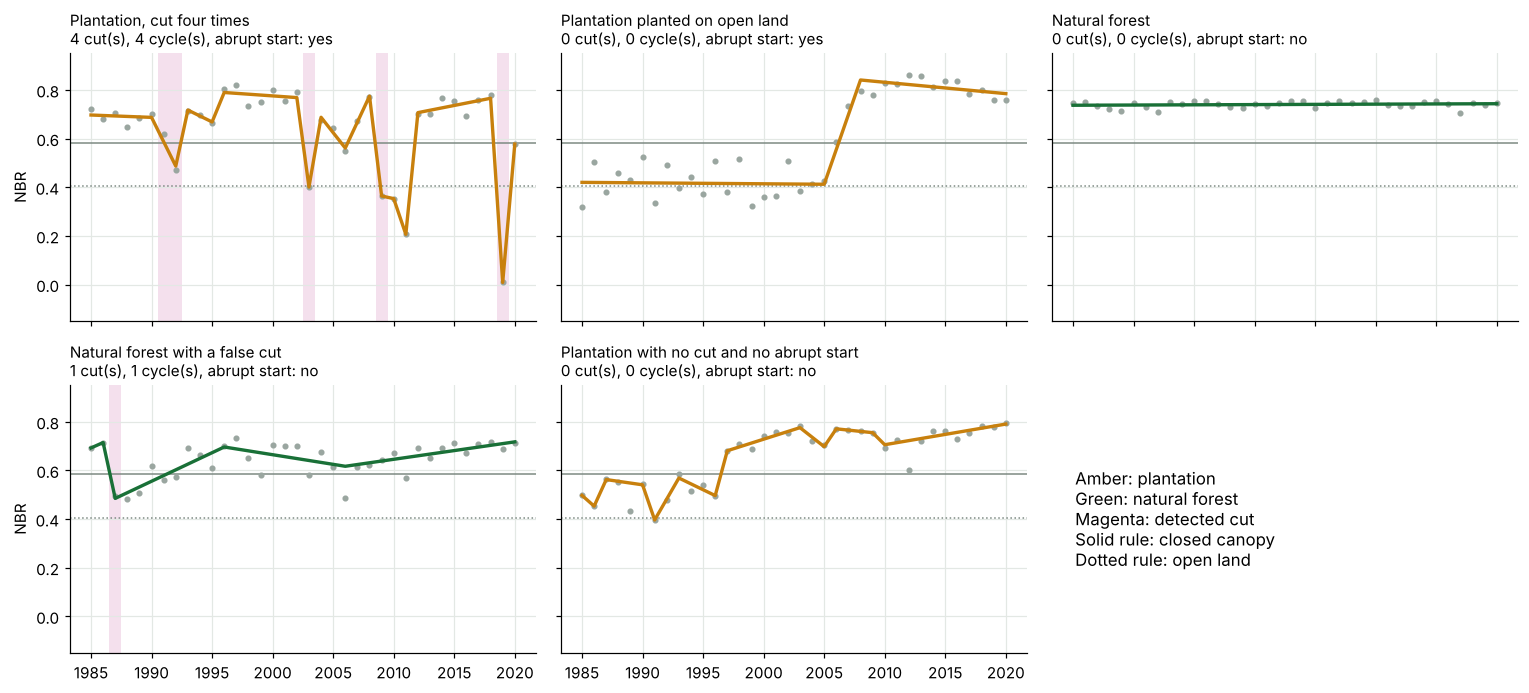

In [6]:
EXAMPLES = {"Plantation, cut four times": "V84039", "Plantation planted on open land": "V80884",
            "Natural forest": "V72258", "Natural forest with a false cut": "V52688",
            "Plantation with no cut and no abrupt start": "V50998"}
fig, axes = plt.subplots(2, 3, figsize=(14, 6.4), sharex=True, sharey=True)
for ax, (title, pid) in zip(axes.ravel(), EXAMPLES.items()):
    tv, vv, t, fit = feat.loc[pid, "seg"]
    colour = PLANT if pts.set_index("pid").loc[pid, "label"] == 1 else FOREST
    for e in feat.loc[pid, "events"]:
        ax.axvspan(e["cut_year"] - 0.5, e["low_year"] + 0.5, color=CUT, alpha=0.15, lw=0)
    ax.axhline(CANOPY, color=GREY, lw=1)
    ax.axhline(OPEN, color=GREY, lw=1, ls=":")
    ax.plot(YEARS, nbr.loc[pid], "o", ms=3, color="#9aa6a0")
    ax.plot(tv, vv, "-", color=colour, lw=2.2)
    f = feat.loc[pid]
    ax.set_title(f"{title}\n{f.n_cuts:.0f} cut(s), {f.n_cycles:.0f} cycle(s), abrupt start: {'yes' if f.abrupt_start else 'no'}",
                 loc="left", fontsize=10)
axes[1, 2].axis("off")
axes[1, 2].text(0.05, 0.5, "Amber: plantation\nGreen: natural forest\nMagenta: detected cut\nSolid rule: closed canopy\nDotted rule: open land",
                fontsize=11, va="center", transform=axes[1, 2].transAxes)
for ax in axes[:, 0]:
    ax.set_ylabel("NBR")
axes[0, 0].set_ylim(-0.15, 0.95)
plt.tight_layout()
plt.show()

## 3. MapBiomas reference points: the harvest history alone

### 3.1 How often each feature appears

Share of plantations and of natural forest with each feature before 2021. The p-values come from Fisher's exact test, and from a logistic regression with standard errors clustered by municipality, which allows for nearby points being alike. Hansen rows are shown for comparison.

In [7]:
NAMES = {"has_cut": "At least one cut", "has_cycle": "At least one cut-and-regrow cycle", "two_plus_cycles": "Two or more cycles",
         "fast_regrowth": "A cycle regrowing within 4 years", "abrupt_start": "Abrupt start on open land",
         "forest_since_1985": "Forest every year since 1985", "hansen_loss": "Hansen loss 2001–2020 (comparison)",
         "hansen_gain": "Hansen gain 2000–2012 (comparison)"}


def odds_ratio(a, b, c, d):
    # Woolf 95% interval; a/b = plantations with/without the feature, c/d = forest with/without
    if min(a, b, c, d) == 0:
        a, b, c, d = a + .5, b + .5, c + .5, d + .5
    orr, se = (a * d) / (b * c), np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    return orr, np.exp(np.log(orr) - 1.96 * se), np.exp(np.log(orr) + 1.96 * se)


def clustered_p(v, y, clusters):
    # p-value of a one-feature logistic regression with standard errors clustered by area
    X = sm.add_constant(np.asarray(v, float)[:, None], has_constant="add")
    fit = sm.GLM(y, X, family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(clusters)[0]})
    return fit.pvalues[1]


def feature_table(d, features=NAMES):
    y, cl = d.label.to_numpy(), d.cluster.to_numpy()
    rows = []
    for f in features:
        v = d[f].fillna(0).astype(int).to_numpy()
        a, b = int(((v == 1) & (y == 1)).sum()), int(((v == 0) & (y == 1)).sum())
        c, e = int(((v == 1) & (y == 0)).sum()), int(((v == 0) & (y == 0)).sum())
        orr, lo, hi = odds_ratio(a, b, c, e)
        rows.append({"feature": NAMES[f], "plantation": a / (a + b), "natural forest": c / (c + e),
                     "odds ratio (95% CI)": f"{num(orr)} ({num(lo)}–{num(hi)})",
                     "p, Fisher": stats.fisher_exact([[a, b], [c, e]])[1],
                     "p, clustered": clustered_p(v, y, cl) if min(a, b, c, e) > 0 else np.nan})
    return pd.DataFrame(rows).set_index("feature")


def show_rates(t):
    return t.assign(**{c: t[c].map(pct) for c in ["plantation", "natural forest"]},
                    **{c: t[c].map(pval) for c in ["p, Fisher", "p, clustered"]})


rates_val = feature_table(val)
show_rates(rates_val)

,plantation,natural forest,odds ratio (95% CI),"p, Fisher","p, clustered"
feature,,,,,
At least one cut,76%,14%,20 (15–26),2.6e-130,2.3e-107
At least one cut-and-regrow cycle,72%,14%,16 (12–21),9.9e-114,2.8e-98
Two or more cycles,39%,2.2%,29 (19–43),1.9e-86,6.4e-64
A cycle regrowing within 4 years,60%,9.9%,14 (11–18),1.3e-95,5.7e-81
Abrupt start on open land,45%,1.1%,74 (43–128),3.2e-117,9.6e-53
Forest every year since 1985,1.6%,45%,0.021 (0.0096–0.044),4.3e-80,1.9e-24
Hansen loss 2001–2020 (comparison),51%,1.6%,66 (42–105),6.7e-134,1.1e-73
Hansen gain 2000–2012 (comparison),49%,0.3%,335 (123–911),4.4e-147,2.8e-29


Every feature separates the two classes on the MapBiomas points: three in four plantations show a cut, against one in seven natural-forest points, where the cuts are false detections. “Forest every year since 1985” runs the other way: 45% of natural forest passes it, but only 1.6% of plantations.

### 3.2 Regrowth speed does not separate

In [8]:
def regrowth_test(d):
    s = d[d.n_cycles >= 1]
    p, f = s[s.label == 1].regrow_years.dropna(), s[s.label == 0].regrow_years.dropna()
    return (f"median years to regrow 80% of the fall: plantation {p.median():.1f} (n = {len(p)}), "
            f"natural forest {f.median():.1f} (n = {len(f)}); Mann-Whitney p = {stats.mannwhitneyu(p, f).pvalue:.2g}")


print("MapBiomas points:", regrowth_test(val))

MapBiomas points: median years to regrow 80% of the fall: plantation 1.7 (n = 304), natural forest 1.8 (n = 184); Mann-Whitney p = 0.39


Among points with a cycle, plantations and natural forest regrow at about the same speed (a median of under two years), likely because NBR recovers quickly under any woody regrowth. The row “A cycle regrowing within 4 years” in 3.1 separates only because it requires a cycle: most cycles regrow within 4 years in both classes.

### 3.3 Summaries of the whole series separate better than counts

AUC of single numbers, with a 95% interval from resampling whole municipalities. Lowest NBR is lower in plantations, so its AUC is given for that direction.

In [9]:
def cluster_ci(y, s, clusters, fn=roc_auc_score, n_boot=1000, seed=SEED):
    # 95% interval of fn(y, s), resampling whole clusters (municipalities or 0.1-degree cells)
    rng = np.random.default_rng(seed)
    codes, uniq = pd.factorize(clusters)
    members = [np.where(codes == i)[0] for i in range(len(uniq))]
    vals = []
    for _ in range(n_boot):
        ii = np.concatenate([members[c] for c in rng.integers(0, len(uniq), len(uniq))])
        if y[ii].min() != y[ii].max():
            vals.append(fn(y[ii], s[ii]))
    return tuple(np.percentile(vals, [2.5, 97.5]))


SUMMARIES = {"s_std": ("Variability (standard deviation)", +1), "s_min": ("Lowest NBR", -1),
             "s_max_drop3": ("Largest 3-year fall", +1), "s_frac_below_forest": ("Share of years below closed canopy", +1),
             "n_cuts": ("Number of cuts", +1), "n_cycles": ("Number of cycles", +1)}


def summary_table(d):
    y, cl = d.label.to_numpy(), d.cluster.to_numpy()
    rows = []
    for f, (name, sign) in SUMMARIES.items():
        v = d[f].astype(float).to_numpy()
        lo, hi = cluster_ci(y, sign * v, cl)
        rows.append({"summary of the yearly NBR": name, "AUC": roc_auc_score(y, sign * v), "95% CI": f"{lo:.2f}–{hi:.2f}",
                     "p, Mann-Whitney": pval(stats.mannwhitneyu(v[y == 1], v[y == 0]).pvalue)})
    return pd.DataFrame(rows).set_index("summary of the yearly NBR")


summary_table(val).round(3)

,AUC,95% CI,"p, Mann-Whitney"
summary of the yearly NBR,,,
Variability (standard deviation),0.968,0.96–0.98,9.8e-190
Lowest NBR,0.932,0.92–0.95,6.7e-162
Largest 3-year fall,0.912,0.90–0.93,2.6e-147
Share of years below closed canopy,0.857,0.84–0.88,4.7e-116
Number of cuts,0.837,0.81–0.86,7.3e-156
Number of cycles,0.810,0.79–0.83,2.5e-136


How much NBR varied over 1985–2020 is the best single number (AUC 0.97): it captures every cut, partial cut and regrowth without needing a threshold. Counting cuts or cycles throws much of that away.

### 3.4 Models on the harvest features alone

Spatial cross-validation: the points are split into 5 folds **by municipality**, so a model is always tested on municipalities it never saw; this is repeated with 5 different splits (25 held-out folds). Logistic regression (LR) and random forest (RF). All models use the same 1,830 points: the MapBiomas points that also have the team's features.

The **team's current features** (`height_stdDev`, `ndvi_aug_oct_mean`, `sag_oct_nov_mean`, `sag_swing_mean` and `ever_farm`) are shown for reference only: they come from the team's 2022 feature table, which uses 2022 imagery, and `ever_farm` comes from the MapBiomas land-cover history.

In [10]:
def full_series(series):
    # the 36 yearly values (gaps interpolated) and their 35 year-to-year changes
    s = series.interpolate(axis=1, limit_direction="both")
    d = s.diff(axis=1).iloc[:, 1:]
    d.columns, s.columns = [f"d{c}" for c in d.columns], [f"y{c}" for c in s.columns]
    return pd.concat([s, d], axis=1)


full = full_series(nbr)
H4 = ["n_cycles", "regrow_speed", "forest_since_1985", "abrupt_start"]
HALL = H4 + ["n_cuts", "years_since_last_cut", "max_drop", "s_frac_below_forest", "s_min", "s_max_drop3"]
HANSEN = ["hansen_loss", "hansen_gain", "tc2000"]
TEAM_FEATURES = ["height_stdDev", "ndvi_aug_oct_mean", "sag_oct_nov_mean", "sag_swing_mean", "ever_farm"]
FULL = list(full.columns)
SETS = {"H4: four harvest features": H4, "H-all: ten harvest features": HALL,
        "H-all + variability (post hoc)": HALL + ["s_std"], "36 yearly values + changes": FULL,
        "Hansen (comparison)": HANSEN, "H-all + Hansen": HALL + HANSEN, "Team's features (reference)": TEAM_FEATURES,
        "Team's features + H-all": TEAM_FEATURES + HALL}

V = val.dropna(subset=TEAM_FEATURES).merge(full, left_on="pid", right_index=True, how="left").reset_index(drop=True)
for f in HALL + HANSEN + ["s_std"]:
    V[f] = V[f].astype(float).fillna(V[f].median())
V[FULL] = V[FULL].fillna(V[FULL].median())
print(f"Model table: {len(V):,} of {len(val):,} MapBiomas points ({len(val) - len(V)} lacks a team feature); "
      f"plantations the MapBiomas 10 m map calls forest among them: {(V.group == 'missed plantation').sum()}")


def make_model(kind, seed=SEED):
    if kind == "LR":
        return make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))
    return RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight="balanced", random_state=seed, n_jobs=-1)


y, municipality = V.label.to_numpy(), V.CD_MUN.to_numpy()
cv_rows, oof = [], {}                                # oof = out-of-fold scores of the first split, for thresholds
for rep in [42, 43, 44, 45, 46]:                     # about 5 minutes
    folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=rep).split(V, y, municipality))
    for name, cols in SETS.items():
        X = V[cols].to_numpy(float)
        for kind in ["LR", "RF"]:
            if cols is FULL and kind == "LR":
                continue
            o = np.full(len(y), np.nan)
            for k, (tr, te) in enumerate(folds):
                o[te] = make_model(kind, rep).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
                cv_rows.append(dict(repeat=rep, fold=k, set=name, model=kind, auc=roc_auc_score(y[te], o[te])))
            if rep == SEED:
                oof[(name, kind)] = o
cv = pd.DataFrame(cv_rows)


def recall_at_fpr(y, s, max_fpr=0.05):
    # best recall with at most max_fpr of natural forest flagged as plantation
    fpr, tpr, thr = roc_curve(y, s)
    k = np.where(fpr <= max_fpr)[0]
    j = k[np.argmax(tpr[k])]
    return tpr[j], fpr[j], thr[j]


auc_val = cv.groupby(["set", "model"]).auc.mean().unstack().reindex(list(SETS))[["LR", "RF"]]
auc_val["RF: plantations caught at ≤ 5% forest flagged"] = [pct(recall_at_fpr(y, oof[(s, "RF")])[0]) for s in auc_val.index]
auc_val.rename(columns={"LR": "LR: mean AUC, 25 folds", "RF": "RF: mean AUC, 25 folds",
                        "RF: plantations caught at ≤ 5% forest flagged": "RF: plantations caught at ≤ 5% forest flagged (first split)"}
               ).round(3).fillna("–")

Model table: 1,830 of 1,831 MapBiomas points (1 lacks a team feature); plantations the MapBiomas 10 m map calls forest among them: 39


model,"LR: mean AUC, 25 folds","RF: mean AUC, 25 folds",RF: plantations caught at ≤ 5% forest flagged (first split)
set,,,
H4: four harvest features,0.908,0.904,66%
H-all: ten harvest features,0.947,0.945,78%
H-all + variability (post hoc),0.973,0.969,87%
36 yearly values + changes,–,0.973,90%
Hansen (comparison),0.933,0.916,79%
H-all + Hansen,0.964,0.959,85%
Team's features (reference),0.909,0.919,64%
Team's features + H-all,0.969,0.969,88%


On its own, the harvest history (H-all, AUC 0.945–0.947) scores above the team's current features (0.909–0.919), and catches 78% of plantations when at most 5% of natural forest is flagged, against 64% for the team's features. The four core features alone are about level with the team's features. Hansen's free loss/gain record alone does almost as well on these points (0.916–0.933) and H-all + Hansen reaches 0.959–0.964, but Hansen transfers worse to Cropin's clearings (4.3). The recall thresholds are picked on the same out-of-fold scores, so they are slightly optimistic.

### 3.5 Plantations that the MapBiomas 10 m map misses

The MapBiomas 10 m map is a separate product from the reference points: an automatic land-cover map (collection 4), whose call at each point is in the team's table. Groups: *caught plantation* (reference plantation, map plantation), *missed plantation* (reference plantation, map forest), *real forest* (both forest), *forest called plantation* (reference forest, map plantation), *other* (the map gives another class).

In [11]:
grp = val.groupby("group").agg(points=("pid", "size"), with_a_cut=("has_cut", "mean"), forest_since_1985=("forest_since_1985", "mean"))
grp = grp.loc[["caught plantation", "missed plantation", "real forest", "forest called plantation", "other"]]
a, b = val[val.group == "missed plantation"].has_cut, val[val.group == "real forest"].has_cut
p = stats.fisher_exact([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]])[1]
print(f"Plantations MapBiomas 10 m calls forest vs forest it calls forest, share with a cut: {a.mean():.0%} vs {b.mean():.0%} (Fisher p = {p:.2g})")
grp.assign(with_a_cut=grp.with_a_cut.map(pct), forest_since_1985=grp.forest_since_1985.map(pct)).rename(
    columns={"with_a_cut": "share with a cut", "forest_since_1985": "share passing 'forest since 1985'"})

Plantations MapBiomas 10 m calls forest vs forest it calls forest, share with a cut: 68% vs 13% (Fisher p = 1.5e-14)


,points,share with a cut,share passing 'forest since 1985'
group,,,
caught plantation,369,78%,1.4%
missed plantation,40,68%,2.5%
real forest,1260,13%,45%
forest called plantation,72,24%,40%
other,90,31%,34%


Two thirds of the plantations the MapBiomas 10 m map calls forest show a cut in their history, so the harvest history can catch some of MapBiomas's misses. Some of this agreement is built in, because the reference labels are drawn from Landsat too.

## 4. Cropin's QC clearings: the independent test

### 4.1 How often each feature appears

The same table on Cropin's clearings. Clustered p-values group clearings into 0.1° cells.

In [12]:
rates_qc = feature_table(qc)
show_rates(rates_qc)

,plantation,natural forest,odds ratio (95% CI),"p, Fisher","p, clustered"
feature,,,,,
At least one cut,35%,20%,2.2 (1.3–3.6),0.0017,0.0067
At least one cut-and-regrow cycle,34%,19%,2.3 (1.4–3.8),0.0016,0.006
Two or more cycles,10%,7.3%,1.5 (0.67–3.2),0.37,0.42
A cycle regrowing within 4 years,26%,14%,2.2 (1.2–3.9),0.0052,0.019
Abrupt start on open land,14%,4.1%,3.8 (1.5–9.8),0.0022,0.0054
Forest every year since 1985,6.1%,30%,0.15 (0.083–0.28),2.9e-10,1.8e-08
Hansen loss 2001–2020 (comparison),10%,1.6%,6.7 (1.6–29),0.0021,0.012
Hansen gain 2000–2012 (comparison),4.8%,0.8%,6.2 (0.81–47),0.049,0.088


QC clearings: median years to regrow 80% of the fall: plantation 1.4 (n = 101), natural forest 2.2 (n = 22); Mann-Whitney p = 0.71


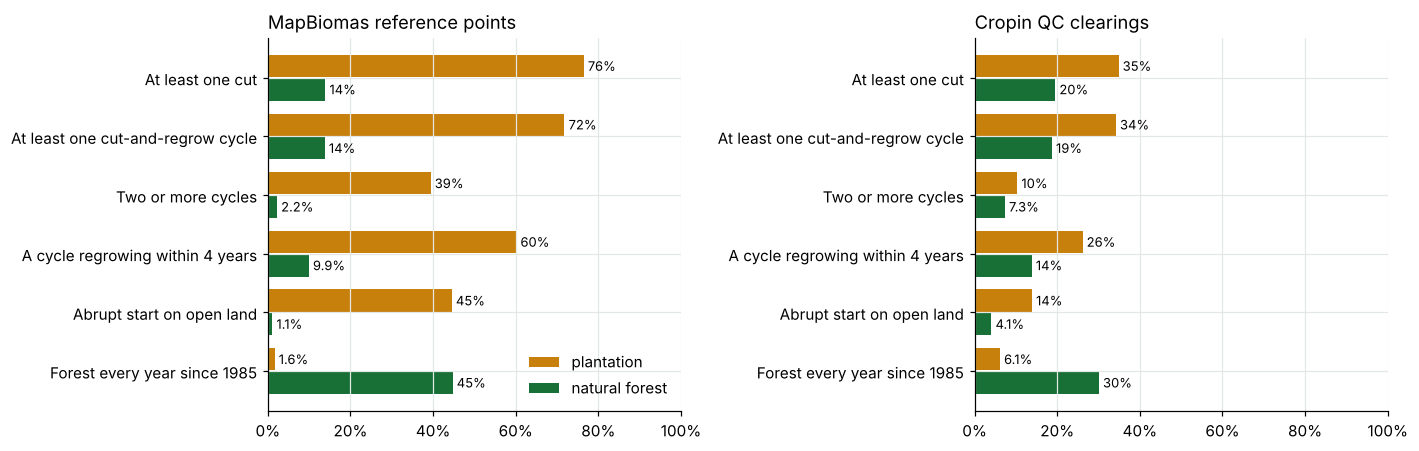

In [13]:
print("QC clearings:", regrowth_test(qc))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
keys = ["has_cut", "has_cycle", "two_plus_cycles", "fast_regrowth", "abrupt_start", "forest_since_1985"]
for ax, (title, t) in zip(axes, [("MapBiomas reference points", rates_val), ("Cropin QC clearings", rates_qc)]):
    t = t.loc[[NAMES[k] for k in keys]][::-1]
    pos = np.arange(len(t))
    ax.barh(pos + 0.2, t["plantation"], height=0.38, color=PLANT, label="plantation")
    ax.barh(pos - 0.2, t["natural forest"], height=0.38, color=FOREST, label="natural forest")
    for i, (p_, f_) in enumerate(zip(t["plantation"], t["natural forest"])):
        ax.text(p_ + 0.01, i + 0.2, pct(p_), va="center", fontsize=8.5)
        ax.text(f_ + 0.01, i - 0.2, pct(f_), va="center", fontsize=8.5)
    ax.set_yticks(pos, t.index)
    ax.set_xlim(0, 1)
    ax.set_title(title, loc="left")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

The harvest-cycle feature is **statistically significant on Cropin's clearings** (34% of plantations vs 19% of forest, p = 0.006 even with clustered errors) but **weak**. “Forest every year since 1985” is the strongest of these yes/no features there (Fisher p = 3 × 10⁻¹⁰); a continuous summary does better (4.2). Two or more cycles, and regrowth time, are not significant.

### 4.2 Single summaries on the QC clearings

In [14]:
summary_table(qc).round(3)

,AUC,95% CI,"p, Mann-Whitney"
summary of the yearly NBR,,,
Variability (standard deviation),0.763,0.71–0.82,1.5e-17
Lowest NBR,0.718,0.66–0.78,1.4e-12
Largest 3-year fall,0.703,0.64–0.76,4e-11
Share of years below closed canopy,0.716,0.66–0.77,2e-12
Number of cuts,0.575,0.53–0.62,0.0026
Number of cycles,0.575,0.52–0.62,0.0024


### 4.3 Models trained on MapBiomas points, applied to the QC clearings

Each model is fitted on all 1,830 MapBiomas points and scored on the 433 clearings it never saw. The threshold is the one that flags at most 5% of natural forest on the MapBiomas points. 95% intervals resample 0.1° cells.

In [15]:
Q = qc.merge(full, left_on="pid", right_index=True, how="left").reset_index(drop=True)
for f in HALL + HANSEN + ["s_std"]:
    Q[f] = Q[f].astype(float).fillna(V[f].median())
Q[FULL] = Q[FULL].fillna(V[FULL].median())
yq = Q.label.to_numpy()
rows = []
for name in ["H4: four harvest features", "H-all: ten harvest features", "H-all + variability (post hoc)",
             "36 yearly values + changes", "Hansen (comparison)", "H-all + Hansen"]:
    cols = SETS[name]
    for kind in ["LR", "RF"]:
        if cols is FULL and kind == "LR":
            continue
        score = make_model(kind).fit(V[cols].to_numpy(float), y).predict_proba(Q[cols].to_numpy(float))[:, 1]
        threshold = recall_at_fpr(y, oof[(name, kind)])[2]
        lo, hi = cluster_ci(yq, score, Q.cluster.to_numpy())
        rows.append({"features": name, "model": kind, "QC AUC": roc_auc_score(yq, score), "95% CI": f"{lo:.2f}–{hi:.2f}",
                     "QC plantations caught": pct((score[yq == 1] >= threshold).mean()),
                     "QC forest flagged": pct((score[yq == 0] >= threshold).mean())})
qc_models = pd.DataFrame(rows).set_index(["features", "model"])
qc_models.round(3)

QC AUC     95% CI QC plantations caught QC forest flagged
features                       model                                                           
H4: four harvest features      LR      0.675  0.62–0.73                   23%              9.8%
                               RF      0.673  0.62–0.73                   25%               12%
H-all: ten harvest features    LR      0.757  0.70–0.81                   33%              7.3%
                               RF      0.743  0.69–0.80                   34%              6.5%
H-all + variability (post hoc) LR      0.796  0.74–0.84                   45%              8.9%
                               RF      0.775  0.72–0.82                   41%               11%
36 yearly values + changes     RF      0.812  0.77–0.85                   43%              5.7%
Hansen (comparison)            LR      0.697  0.64–0.75                   28%              4.9%
                               RF      0.684  0.63–0.74                   26%              5.7%
H-all + Hansen                 LR      0.773  0.72–0.82                   38%              6.5%
                               RF      0.766  0.72–0.82                   34%              5.7%

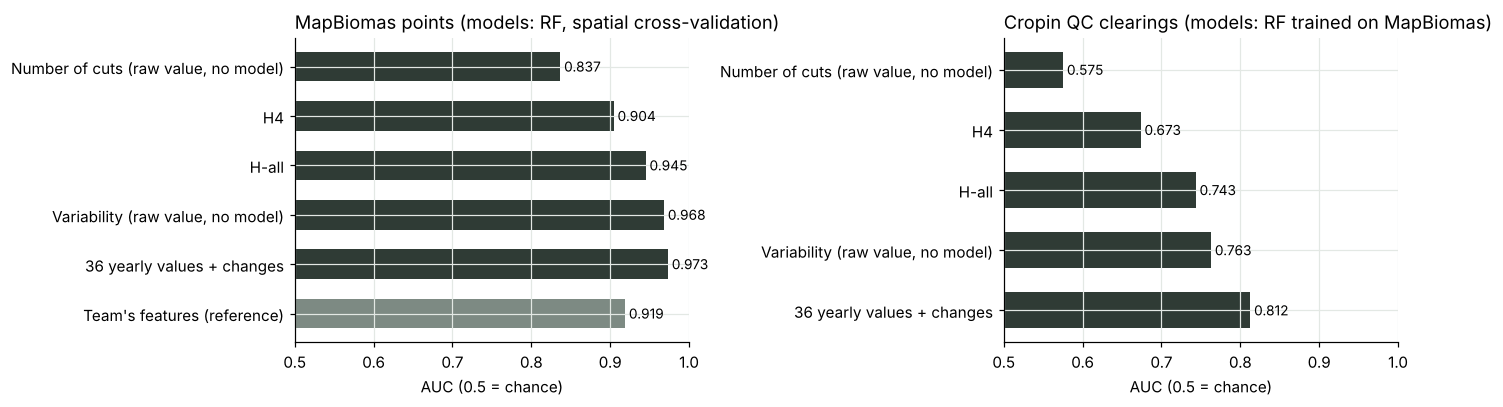

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
single_val, single_qc = summary_table(val)["AUC"], summary_table(qc)["AUC"]
panels = [("MapBiomas points (models: RF, spatial cross-validation)",
           {"Number of cuts (raw value, no model)": single_val["Number of cuts"], "H4": auc_val.loc["H4: four harvest features", "RF"],
            "H-all": auc_val.loc["H-all: ten harvest features", "RF"], "Variability (raw value, no model)": single_val["Variability (standard deviation)"],
            "36 yearly values + changes": auc_val.loc["36 yearly values + changes", "RF"],
            "Team's features (reference)": auc_val.loc["Team's features (reference)", "RF"]}),
          ("Cropin QC clearings (models: RF trained on MapBiomas)",
           {"Number of cuts (raw value, no model)": single_qc["Number of cuts"], "H4": qc_models.loc[("H4: four harvest features", "RF"), "QC AUC"],
            "H-all": qc_models.loc[("H-all: ten harvest features", "RF"), "QC AUC"], "Variability (raw value, no model)": single_qc["Variability (standard deviation)"],
            "36 yearly values + changes": qc_models.loc[("36 yearly values + changes", "RF"), "QC AUC"]})]
for ax, (title, vals) in zip(axes, panels):
    names = list(vals)[::-1]
    ax.barh(names, [vals[n] - 0.5 for n in names], left=0.5, color=[GREY if "Team" in n else "#2f3b35" for n in names], height=0.6)
    for i, n in enumerate(names):
        ax.text(vals[n] + 0.005, i, f"{vals[n]:.3f}", va="center", fontsize=9)
    ax.set_xlim(0.5, 1.0)
    ax.set_title(title, loc="left")
    ax.set_xlabel("AUC (0.5 = chance)")
plt.tight_layout()
plt.show()

On Cropin's clearings, counting cuts is only a little better than chance (0.58), but summaries of the whole series work: NBR variability alone (picked after the first results) reaches 0.76, and the 36 yearly values reach 0.81, without ever seeing a QC clearing in training. In practice H-all would clear about a third of the plantation false alarms while flagging 6–7% of real forest clearings as plantation. Hansen alone transfers less well (0.68–0.70), and H-all + Hansen reaches 0.77. All intervals exclude 0.5.

For comparison, the team's midterm slides report that on these same clearings MapBiomas (Collection 9, 2020) catches 4% of the plantations while flagging 2% of forest, and Google's Natural Forests layer catches 23% while flagging 6% (not recomputed here).

### 4.4 Why the QC clearings are harder

In [17]:
# clearing size: plantation clearings in four classes, forest clearings in three (no class small enough to single clearings out)
qc_pl, qc_fo = qc[qc.label == 1], qc[qc.label == 0]
pl_size = pd.cut(qc_pl.qc_area_m2, [0, 300, 900, 2700, 1e9], labels=["under 300 m²", "300–900 m²", "900–2,700 m²", "over 2,700 m²"])
fo_size = pd.cut(qc_fo.qc_area_m2, [0, 300, 900, 1e9], labels=["under 300 m²", "300–900 m²", "over 900 m²"])
for name, d, size in [("Plantation", qc_pl, pl_size), ("Natural-forest", qc_fo, fo_size)]:
    print(f"{name} clearings with a cut, by size: "
          + ", ".join(f"{k} {pct(g.mean())} (n = {len(g)})" for k, g in d.groupby(size, observed=True).has_cut))
recent = qc.last_cut_year.between(2010, 2020)
print(f"Share with a cut in 2010–2020: QC plantations {recent[qc.label == 1].mean():.0%}, QC forest {recent[qc.label == 0].mean():.0%}")
fv, fq = val[val.label == 0], qc[qc.label == 0]
for col, what in [("has_cut", "with a false cut"), ("forest_since_1985", "passing 'forest since 1985'")]:
    p_ = stats.fisher_exact([[fq[col].sum(), len(fq) - fq[col].sum()], [fv[col].sum(), len(fv) - fv[col].sum()]])[1]
    print(f"Natural forest {what}: QC {fq[col].mean():.0%}, MapBiomas {fv[col].mean():.0%} (Fisher p = {p_:.2g})")

Plantation clearings with a cut, by size: under 300 m² 33% (n = 159), 300–900 m² 34% (n = 85), 900–2,700 m² 36% (n = 55), over 2,700 m² 64% (n = 11)
Natural-forest clearings with a cut, by size: under 300 m² 18% (n = 65), 300–900 m² 24% (n = 38), over 900 m² 15% (n = 20)
Share with a cut in 2010–2020: QC plantations 8%, QC forest 0%
Natural forest with a false cut: QC 20%, MapBiomas 14% (Fisher p = 0.11)
Natural forest passing 'forest since 1985': QC 30%, MapBiomas 45% (Fisher p = 0.0017)


**Median yearly NBR by group** (shaded: the middle half of the points). Cuts fall in different years at different points, so the medians are smooth. On the MapBiomas points, plantations that the 10 m map also calls plantation sit below forest until 2006 and above it from 2007, and spread wider in every year; plantations the map calls forest stay a little below forest. On Cropin's clearings the gap is small and closes by about 2012.

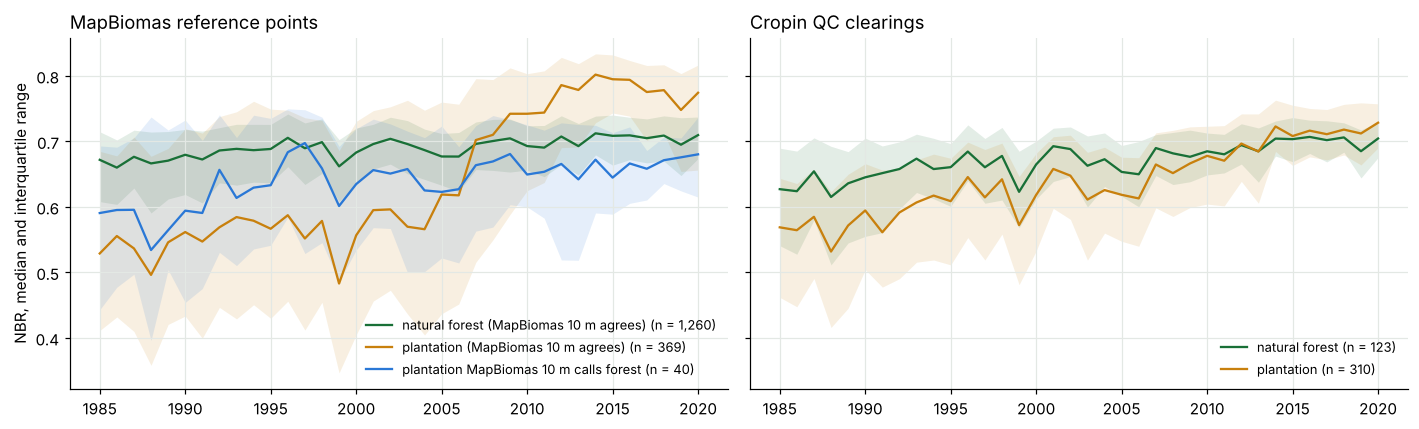

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
panels = [("MapBiomas reference points", [("real forest", FOREST, "natural forest (MapBiomas 10 m agrees)"),
                                          ("caught plantation", PLANT, "plantation (MapBiomas 10 m agrees)"),
                                          ("missed plantation", "#2a78d6", "plantation MapBiomas 10 m calls forest")], val, "group"),
          ("Cropin QC clearings", [(0, FOREST, "natural forest"), (1, PLANT, "plantation")], qc, "label")]
for ax, (title, groups, d, col) in zip(axes, panels):
    for key, colour, lab in groups:
        s = nbr.loc[d[d[col] == key].pid]
        ax.fill_between(YEARS, s.quantile(0.25), s.quantile(0.75), color=colour, alpha=0.12, lw=0)
        ax.plot(YEARS, s.median(), color=colour, label=f"{lab} (n = {len(s):,})")
    ax.set_title(title, loc="left")
    ax.legend(loc="lower right", fontsize=8.5)
axes[0].set_ylabel("NBR, median and interquartile range")
plt.tight_layout()
plt.show()

- **Small clearings.** The median clearing covers under a third of a Landsat pixel. Plantation clearings show a cut 33–36% of the time at every size up to 2,700 m² (three pixels); only the 11 larger ones come near MapBiomas plantations (64% vs 76%).
- **No recent rotation at 30 m.** Only 8% of QC plantations show a cut in 2010–2020, and by about 2012 their median NBR has reached that of the QC forest: at 30 m they look like older woodlots.
- **Forest in a more disturbed setting.** QC forest fails “forest since 1985” more often than MapBiomas forest (70% vs 55%, p = 0.002); its false-cut rate is higher too (20% vs 14%) but not significantly (p = 0.11). Plausibly it sits in farm landscapes.

## 5. Using the harvest history

### 5.1 “Forest every year since 1985” as a veto

The feature can only cancel a plantation call. *Tolerance* is the number of years NBR may dip below closed canopy. The last column ignores 1985–1992: about half of the natural-forest points with a false cut have all their cuts in those years (section 6).

In [19]:
def passes_from(pid, start):
    # no cut from `start` on and no despiked yearly value below closed canopy from `start` on
    v = nbr.loc[pid].to_numpy(float)
    t, yv = YEARS[np.isfinite(v)], despike(v[np.isfinite(v)])
    return int(sum(e["cut_year"] >= start for e in feat.loc[pid, "events"]) == 0 and np.sum(yv[t >= start] < CANOPY) == 0)


rows = {}
mb = val.mb_pred == 2                                # MapBiomas 10 m calls the point plantation
for label, tol, start in [("tolerance 0", 0, 1985), ("tolerance 1", 1, 1985), ("tolerance 2", 2, 1985), ("1993–2020 only", 0, 1993)]:
    if start == 1985:
        pv = ((val.n_cuts == 0) & (val.years_below_forest <= tol)).astype(int)
        pq = ((qc.n_cuts == 0) & (qc.years_below_forest <= tol)).astype(int)
    else:
        pv, pq = val.pid.map(lambda p: passes_from(p, start)), qc.pid.map(lambda p: passes_from(p, start))
    rows[label] = {"MapBiomas: forest protected": pct(pv[val.label == 0].mean()),
                   "MapBiomas: plantations wrongly vetoed": pct(pv[val.label == 1].mean()),
                   "QC: forest protected": pct(pq[qc.label == 0].mean()),
                   "QC: plantations wrongly vetoed": pct(pq[qc.label == 1].mean()),
                   f"MapBiomas 10 m wrong plantation calls cancelled (of {int((mb & (val.label == 0)).sum())})": int(pv[mb & (val.label == 0)].sum()),
                   f"MapBiomas 10 m correct plantation calls lost (of {int((mb & (val.label == 1)).sum())})": int(pv[mb & (val.label == 1)].sum())}
s = oof[("H-all: ten harvest features", "RF")]
flag, passes = s >= recall_at_fpr(y, s)[2], V.forest_since_1985.to_numpy() == 1
print(f"Inside the H-all model (RF, ≤ 5% forest flagged): {int((flag & (y == 0) & passes).sum())} of its {int((flag & (y == 0)).sum())} "
      f"natural-forest flags pass the veto; {int((flag & (y == 1) & passes).sum())} of its {int((flag & (y == 1)).sum())} plantation flags would be cancelled")
pd.DataFrame(rows)

Inside the H-all model (RF, ≤ 5% forest flagged): 0 of its 67 natural-forest flags pass the veto; 0 of its 333 plantation flags would be cancelled


,tolerance 0,tolerance 1,tolerance 2,1993–2020 only
MapBiomas: forest protected,45%,57%,62%,59%
MapBiomas: plantations wrongly vetoed,1.6%,2.6%,3.3%,4.0%
QC: forest protected,30%,41%,50%,47%
QC: plantations wrongly vetoed,6.1%,13%,14%,13%
MapBiomas 10 m wrong plantation calls cancelled (of 72),29,37,39,43
MapBiomas 10 m correct plantation calls lost (of 369),5,9,10,14


At tolerance 0 the veto protects 45% of natural forest and wrongly cancels 1.6% of plantations on the MapBiomas points; on Cropin's clearings it protects only 30% and wrongly cancels 6.1%. As a filter on the MapBiomas 10 m map it cancels 29 of its 72 wrong plantation calls and loses 5 of 369 correct ones. It helps only on top of a map or model without the harvest history: inside the H-all model none of the flagged forest points passes it. Ignoring the pre-1993 years is not a free fix: it protects more forest but vetoes more than twice as many plantations. Use it only to cancel a plantation call, never to make one.

### 5.2 The best way to use the series

Each comparison scores the same points two ways and gives the AUC difference with a 95% interval (resampling municipalities, or 0.1° cells for QC). Positive favours the first option. The yearly composites (dry season Apr–Sep, wet season Oct–Mar, yearly maximum) and NDVI each get their own Hansen-based levels.

In [20]:
def cut_counts(series, drop, max_segments=18):
    canopy, open_level, _, _ = levels(series, drop)
    return all_features(series, canopy, open_level, drop=drop, max_segments=max_segments)["n_cuts"]


SCORES = {"cut count": feat.n_cuts, "variability": feat.s_std, "largest 3-year fall": feat.s_max_drop3,
          "cut count, NDVI": cut_counts(read_series("ndvi_median"), drop=0.15),       # these take a few minutes
          "cut count, 6 segments": cut_counts(nbr, DROP, max_segments=6),
          "cut count, dry-season median": cut_counts(read_series("nbr_dry_median"), DROP),
          "cut count, wet-season median": cut_counts(read_series("nbr_wet_median"), DROP),
          "cut count, yearly maximum": cut_counts(read_series("nbr_max"), DROP)}
COMPARISONS = [("variability", "cut count"), ("largest 3-year fall", "cut count"), ("cut count", "cut count, NDVI"),
               ("cut count", "cut count, 6 segments"), ("cut count", "cut count, dry-season median"),
               ("cut count", "cut count, wet-season median"), ("cut count", "cut count, yearly maximum")]


rates = {}
for k, sc in SCORES.items():
    if k.startswith("cut count"):
        rates[k] = {f"{name}: {lab} with a cut": pct((sc.reindex(d[d.label == l].pid) >= 1).mean())
                    for name, d in [("MapBiomas", val), ("QC", qc)] for l, lab in [(1, "plantations"), (0, "forest")]}
display(pd.DataFrame(rates).T)


def auc_diff(yy, ss):
    return roc_auc_score(yy, ss[:, 0]) - roc_auc_score(yy, ss[:, 1])


rows = []
for a_, b_ in COMPARISONS:
    row = {"comparison": f"{a_} vs {b_}"}
    for name, d in [("MapBiomas", df[df.dataset == "val"]), ("QC", df[df.dataset == "qc"])]:
        yy = d.label.to_numpy()
        ss = np.c_[SCORES[a_].reindex(d.pid).fillna(0), SCORES[b_].reindex(d.pid).fillna(0)]
        lo, hi = cluster_ci(yy, ss, d.cluster.to_numpy(), fn=auc_diff)
        row[f"{name}: AUC difference (95% CI)"] = f"{auc_diff(yy, ss):+.3f} ({lo:+.3f} to {hi:+.3f})"
    rows.append(row)
pd.DataFrame(rows).set_index("comparison")

,MapBiomas: plantations with a cut,MapBiomas: forest with a cut,QC: plantations with a cut,QC: forest with a cut
cut count,76%,14%,35%,20%
"cut count, NDVI",70%,21%,28%,22%
"cut count, 6 segments",65%,11%,26%,14%
"cut count, dry-season median",78%,21%,45%,29%
"cut count, wet-season median",78%,19%,44%,20%
"cut count, yearly maximum",60%,9.1%,21%,9.8%


,MapBiomas: AUC difference (95% CI),QC: AUC difference (95% CI)
comparison,,
variability vs cut count,+0.132 (+0.111 to +0.154),+0.188 (+0.138 to +0.233)
largest 3-year fall vs cut count,+0.075 (+0.059 to +0.092),+0.128 (+0.089 to +0.167)
"cut count vs cut count, NDVI",+0.066 (+0.042 to +0.092),+0.042 (-0.013 to +0.096)
"cut count vs cut count, 6 segments",+0.058 (+0.041 to +0.078),+0.017 (-0.017 to +0.050)
"cut count vs cut count, dry-season median",+0.014 (-0.007 to +0.038),-0.013 (-0.063 to +0.038)
"cut count vs cut count, wet-season median",+0.008 (-0.017 to +0.031),-0.059 (-0.118 to +0.006)
"cut count vs cut count, yearly maximum",+0.072 (+0.046 to +0.095),+0.017 (-0.033 to +0.071)


In [21]:
segs = feat.seg.dropna()
rows = []
for drop in [0.10, 0.15, 0.20, 0.25, 0.30]:
    counts_ = pd.Series({pid: len(find_cuts(*seg, drop=drop)) for pid, seg in segs.items()})
    row = {"NBR drop": drop}
    for name, d in [("MapBiomas", val), ("QC", qc)]:
        d = d[d.pid.isin(counts_.index)]
        c, yy = counts_.reindex(d.pid).to_numpy(), d.label.to_numpy()
        row[f"{name}: plantations with a cut"] = pct((c[yy == 1] >= 1).mean())
        row[f"{name}: forest with a cut"] = pct((c[yy == 0] >= 1).mean())
        row[f"{name}: AUC"] = round(roc_auc_score(yy, c), 3)
    rows.append(row)
pd.DataFrame(rows).set_index("NBR drop")

,MapBiomas: plantations with a cut,MapBiomas: forest with a cut,MapBiomas: AUC,QC: plantations with a cut,QC: forest with a cut,QC: AUC
NBR drop,,,,,,
0.10,87%,35%,0.836,62%,41%,0.623
0.15,84%,23%,0.851,51%,27%,0.618
0.20,76%,14%,0.837,35%,20%,0.575
0.25,66%,7.9%,0.802,20%,14%,0.528
0.30,56%,4.0%,0.763,8.4%,3.3%,0.526


- **Feed continuous summaries to a model, not counts.** Variability beats the cut count by +0.13 AUC on MapBiomas points and +0.19 on QC. The two summary-versus-count comparisons are the only ones significant on QC.
- **Use NBR, not NDVI**, which saturates over canopy (+0.07 AUC on MapBiomas points).
- **Allow enough segments.** With 6, the cut count loses about 0.06 AUC: a pixel can hold only about two cuts.
- **Use the yearly median or the wet-season median, not the dry season or the yearly maximum.** The dry-season median finds more false cuts in forest (21% vs 14%, though its AUC is not significantly lower), likely because deciduous forest loses its leaves in the dry season; the yearly maximum keeps the pre-cut image and misses cuts (−0.07 AUC). The wet-season median is level with the yearly median on the MapBiomas points and somewhat better on QC (not significant).
- **Keep the drop threshold near 0.15–0.20 NBR.** At 0.10 a third of natural forest shows a “cut”; at 0.25 the cut count is near chance on QC (AUC 0.53), and at 0.30 only about half of plantations show a cut. 0.15 scores slightly above the 0.20 used here.

## 6. What fools it

The MapBiomas reference history is used here only to split the results, never as a feature.

In [22]:
H = val[[f"CLASS_{y}" for y in range(1985, 2023)]].to_numpy()            # 3 = forest, 9 = plantation
first_plantation = np.array([1985 + int(np.argmax(r == 9)) if (r == 9).any() else np.nan for r in H])
period = pd.cut(pd.Series(first_plantation).where(val.label == 1), [1984, 1985, 2000, 2013, 2022],
                labels=["plantation already in 1985", "established 1986–2000", "established 2001–2013",
                        "established 2014–2020 (first rotation)"])
history_kind = np.where(val.label == 0, np.where((H[:, :36] == 3).all(axis=1), "forest every year 1985–2020",
                                                 "non-forest in some year"), None)
km_to_curitiba = np.hypot((val.lon + 49.27) * 111 * np.cos(np.deg2rad(25.43)), (val.lat + 25.43) * 111)
zone = np.where(val.label == 0, np.where(km_to_curitiba <= 80, "within 80 km of Curitiba (bracatinga zone)", "elsewhere"), None)
rows = []
for stratum, key in [("Plantations, by establishment period", period), ("Natural forest, by reference history", history_kind),
                     ("Natural forest, by zone", zone)]:
    for k, d in val.groupby(pd.Series(key, index=val.index), sort=True):
        rows.append({"stratum": stratum, "group": k, "points": len(d), "with a cut": pct(d.has_cut.mean()),
                     "pass 'forest since 1985'": pct(d.forest_since_1985.mean()), "abrupt start": pct(d.abrupt_start.mean())})
fc_, pc_ = val[(val.label == 0) & (val.has_cut == 1)], val[(val.label == 1) & (val.has_cut == 1)]
print(f"Points with a cut whose cuts all fall before 1993: natural forest {(fc_.last_cut_year <= 1992).mean():.0%} (n = {len(fc_)}), "
      f"plantations {(pc_.last_cut_year <= 1992).mean():.0%} (n = {len(pc_)})")
pd.DataFrame(rows).set_index(["stratum", "group"])

Points with a cut whose cuts all fall before 1993: natural forest 48% (n = 195), plantations 8% (n = 328)


points with a cut pass 'forest since 1985' abrupt start
stratum                              group                                                                                              
Plantations, by establishment period plantation already in 1985                     129        94%                     3.1%          34%
                                     established 1986–2000                           80        80%                       0%          50%
                                     established 2001–2013                          204        67%                     1.0%          50%
                                     established 2014–2020 (first rotation)          16        44%                     6.2%          38%
Natural forest, by reference history forest every year 1985–2020                   1261        12%                      49%         0.2%
                                     non-forest in some year                        141        33%                     7.1%         8.5%
Natural forest, by zone              elsewhere                                     1255        14%                      43%         1.0%
                                     within 80 km of Curitiba (bracatinga zone)     147        12%                      57%         2.0%

- **Early years.** About half (48%) of the natural-forest points with a cut have all their cuts in 1986–1992, against 8% of plantations with a cut. Only Landsat 4/5 cover those years and Hansen cannot check them.
- **First-rotation stands are missed**: the later a plantation was established, the less often a cut is seen; abrupt start catches part of the newer ones.
- **Forest that the reference shows as non-forest in some year** (for example regrowth on former farmland) has nearly three times the false-cut rate of forest that was forest every year.
- **Bracatinga** (a native tree that farmers around Curitiba cut on short rotations) shows no excess of false cuts; the zone is a crude proxy.

## 7. For reference: adding the history to the team's model

The team's features come from its 2022 feature table, which includes 2022 imagery, and its `ever_farm` comes from the MapBiomas land-cover history. A model that combines them with the harvest history is therefore **not** limited to data before 2021; the harvest history alone is.

In [23]:
a = cv[(cv.set == "Team's features + H-all")].set_index(["repeat", "fold", "model"]).auc
b = cv[(cv.set == "Team's features (reference)")].set_index(["repeat", "fold", "model"]).auc
gain = (a - b).groupby("model").agg(["mean", lambda d: f"{(d > 0).sum()}/{len(d)}"])
gain.columns = ["AUC gain", "folds improved"]
s = oof[("Team's features + H-all", "RF")]
flag = s >= recall_at_fpr(y, s)[2]
map_flag, is_pl, missed = (V.mb_pred == 2).to_numpy(), y == 1, (V.group == "missed plantation").to_numpy()
b_, c_ = int((flag & ~map_flag & is_pl).sum()), int((~flag & map_flag & is_pl).sum())
print(f"At ≤ 5% forest flagged, team + H-all (RF) flags {flag[is_pl].mean():.0%} of plantations; the MapBiomas 10 m map flags "
      f"{map_flag[is_pl].mean():.0%} at {map_flag[~is_pl].mean():.1%} of forest (exact McNemar p = {stats.binomtest(b_, b_ + c_).pvalue:.2f}). "
      f"Plantations the map calls forest, caught: {int(flag[missed].sum())} of {int(missed.sum())}")
pd.concat([b.groupby("model").mean().rename("team's features"), a.groupby("model").mean().rename("team's features + H-all"), gain], axis=1).round(3)

At ≤ 5% forest flagged, team + H-all (RF) flags 88% of plantations; the MapBiomas 10 m map flags 86% at 5.1% of forest (exact McNemar p = 0.49). Plantations the map calls forest, caught: 26 of 39


,team's features,team's features + H-all,AUC gain,folds improved
model,,,,
LR,0.909,0.969,0.060,25/25
RF,0.919,0.969,0.051,25/25


Adding the ten harvest features lifts the team's model from 0.909–0.919 to 0.969 and improves all 25 held-out folds, for both models. At about the MapBiomas 10 m map's own false-alarm rate, the combined model flags 88% of plantations against the map's 86%, with no significant difference (the team's features alone: 64%), and it catches 26 of the 39 plantations the map calls forest.

## 8. Against Cropin's own tools: its forest layer and SAG

Cropin's Earth Engine scripts (`Google Earth Engine Base/` in this repository) set where an alert can happen, a **forest layer**, and how a plantation is called, **SAG**, a Sentinel-2 colour index. Earth Engine is not available to this notebook, so it uses stand-ins:

- **Forest layer:** the MapBiomas 10 m map calls the point forest (from the team's table) and Meta's canopy height is at least 4 m (mean over about 12 m around the point, in `canopy_height.csv`). It is approximate in both directions: it lacks the MapBiomas 30 m and JRC forest maps that Cropin's layer also needs and uses the team's 10 m map instead of Cropin's, yet its canopy test is stricter in places.
- **SAG:** the team's SAG values at the MapBiomas points (Sentinel-2, 2022), not Cropin's SAG score over 2019–2025. There are none for the QC clearings.

`harvest_cycles/gee/cropin_layers_at_points.js` exports Cropin's forest-layer parts and SAG observations at every point; once its two files are in `public_data/harvest_cycles/`, the cells below use them instead (the text describes the stand-in results).

### 8.1 Natural forest inside the forest layer

At the usual threshold (at most 5% of all MapBiomas forest flagged), how much natural forest *inside* the layer is flagged as plantation, and how many plantations inside it are caught?

In [24]:
chm = pd.read_csv(DATA / "canopy_height.csv", index_col="pid")     # Meta canopy height, mean over about 12 m
V["canopy_m"], qc["canopy_m"] = V.pid.map(chm.chm_mean), qc.pid.map(chm.chm_mean)
exact_layer = DATA / "cropin_forest_layer.csv"                       # optional, from the Earth Engine script
if exact_layer.exists():
    L = pd.read_csv(exact_layer, index_col="pid")
    # Cropin's "Final Forest Mask": score >= 0.75, not a MapBiomas 10 m plantation, MapBiomas 10 m beta forest, canopy >= 4 m
    L_in = (L.forest_score >= 0.75) & (L.mb_plantation_10m == 0) & (L.mb_forest_10m_beta == 1) & (L.canopy_10m >= 4)
    in_layer = V.pid.map(L_in).fillna(False).astype(bool).to_numpy()
    print(f"Cropin's forest layer, from {exact_layer.name}: {V.pid.isin(L.index).mean():.0%} of MapBiomas points found; "
          f"{qc.pid.map(L_in).fillna(False).astype(bool).mean():.0%} of QC clearings are inside it")
else:
    in_layer = ((V.mb_pred == 1) & (V.canopy_m >= 4)).to_numpy()    # stand-in: MapBiomas 10 m forest, canopy >= 4 m
    print(f"Stand-in forest layer. Check: {(qc.canopy_m >= 4).mean():.0%} of QC clearings, which Cropin's alerts should place "
          "inside its real layer, pass the canopy test")
f_in, p_in = in_layer & (y == 0), in_layer & (y == 1)
print(f"Inside the layer: {f_in.sum():,} of {(y == 0).sum():,} natural-forest points and {p_in.sum()} of {(y == 1).sum()} plantations; "
      f"“forest since 1985” protects {V.forest_since_1985.to_numpy()[f_in].mean():.0%} of that forest")


def share_ci(flags, clusters, n_boot=1000, seed=SEED):
    # 95% interval of a share, resampling whole clusters
    rng = np.random.default_rng(seed)
    codes, uniq = pd.factorize(clusters)
    members = [np.where(codes == i)[0] for i in range(len(uniq))]
    return np.percentile([flags[np.concatenate([members[c] for c in rng.integers(0, len(uniq), len(uniq))])].mean()
                          for _ in range(n_boot)], [2.5, 97.5])


rows = {}
for name in ["H-all: ten harvest features", "36 yearly values + changes", "Hansen (comparison)",
             "Team's features (reference)", "Team's features + H-all"]:
    s = oof[(name, "RF")]
    flag = s >= recall_at_fpr(y, s)[2]
    lo, hi = share_ci(flag[f_in], municipality[f_in])
    rows[name] = {"all MapBiomas forest flagged": pct(flag[y == 0].mean()),
                  "forest inside the layer flagged (95% CI)": f"{pct(flag[f_in].mean())} ({lo:.1%}–{hi:.1%})",
                  "plantations inside the layer caught": f"{int(flag[p_in].sum())} of {int(p_in.sum())}",
                  "QC forest flagged": qc_models.loc[(name, "RF"), "QC forest flagged"] if (name, "RF") in qc_models.index else "–"}
pd.DataFrame(rows).T

Stand-in forest layer. Check: 85% of QC clearings, which Cropin's alerts should place inside its real layer, pass the canopy test
Inside the layer: 1,124 of 1,402 natural-forest points and 28 of 428 plantations; “forest since 1985” protects 48% of that forest


,all MapBiomas forest flagged,forest inside the layer flagged (95% CI),plantations inside the layer caught,QC forest flagged
H-all: ten harvest features,4.8%,3.2% (2.2%–4.3%),14 of 28,6.5%
36 yearly values + changes,4.8%,2.9% (2.0%–3.9%),12 of 28,5.7%
Hansen (comparison),5.0%,3.3% (2.3%–4.5%),14 of 28,5.7%
Team's features (reference),4.9%,2.9% (1.9%–4.1%),7 of 28,–
Team's features + H-all,4.9%,3.6% (2.4%–4.7%),19 of 28,–


Inside the stand-in layer the harvest-history models flag about 3% of natural forest, measured on over 1,100 forest points instead of QC's 123; QC forest, which is forest being cleared, is flagged 5.7–6.5%. The layer holds only 28 plantations, the map's misses that still have tall canopy, and the harvest history catches about half of them. The stand-in is only approximate: 15% of the QC clearings, which Cropin's alerts should place inside its real layer, fail its canopy test.

### 8.2 Harvest history on top of SAG

The same spatial cross-validation as in 3.4, with SAG alone, the ten harvest features alone, and both.

In [25]:
def cropin_sag_posterior(obs, seasons=range(2019, 2026), mean_p=160, mean_n=150, sd=9):
    # Cropin's rule: each season starts at 0.5 and is updated with every SAG value in time order (plantation 160 +- 9,
    # other 150 +- 9), clamped to 0.1-0.9; the score is the mean over the seasons (0.5 for a season with no value).
    # This is Cropin's per-pixel posterior at the point; near image-footprint edges their area maps may drop a season.
    post = {}
    obs = obs.dropna(subset=["SAG"])                                 # a blank value carries the previous posterior
    for (pid, season), g in obs.sort_values(["time", "image"]).groupby(["pid", "season"]):
        p = 0.5
        for x in g.SAG.to_numpy(float):
            a, b = np.exp(-(x - mean_p) ** 2 / (2 * sd ** 2)) * p, np.exp(-(x - mean_n) ** 2 / (2 * sd ** 2)) * (1 - p)
            p = min(max(a / (a + b), 0.1), 0.9)
        post[(pid, season)] = p
    return pd.Series(post).unstack().reindex(columns=list(seasons)).fillna(0.5).mean(axis=1)


SAG_COLS = ["sag_oct_nov_mean", "sag_swing_mean", "sag_year_mean"]   # the team's SAG values, 2022
sag_file = DATA / "cropin_sag_observations.csv"                      # optional, from the Earth Engine script
if sag_file.exists():
    sag_score = cropin_sag_posterior(pd.read_csv(sag_file))
    V["sag_cropin"], Q["sag_cropin"] = V.pid.map(sag_score).fillna(0.5), Q.pid.map(sag_score).fillna(0.5)
    SAG_COLS = ["sag_cropin"]
    print(f"Cropin's SAG score, from {sag_file.name}: SAG values for {V.pid.isin(sag_score.index).mean():.0%} of MapBiomas points")
else:
    print("SAG: the team's 2022 values (sag_oct_nov_mean, sag_swing_mean, sag_year_mean)")
SAG_SETS = {"SAG": SAG_COLS, "SAG + H-all": SAG_COLS + HALL}
rows, sag_oof = [], {}
for rep in [42, 43, 44, 45, 46]:                                     # same folds as in 3.4
    folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=rep).split(V, y, municipality))
    for name, cols in SAG_SETS.items():
        X = V[cols].to_numpy(float)
        for kind in ["LR", "RF"]:
            o = np.full(len(y), np.nan)
            for k, (tr, te) in enumerate(folds):
                o[te] = make_model(kind, rep).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
                rows.append(dict(repeat=rep, fold=k, set=name, model=kind, auc=roc_auc_score(y[te], o[te])))
            if rep == SEED:
                sag_oof[(name, kind)] = o
sag_oof.update({("H-all", k): oof[("H-all: ten harvest features", k)] for k in ["LR", "RF"]})
scv = pd.concat([pd.DataFrame(rows), cv[cv.set == "H-all: ten harvest features"].assign(set="H-all")])
by_fold = scv.set_index(["set", "model", "repeat", "fold"]).auc

table = {}
for name in ["SAG", "H-all", "SAG + H-all"]:
    s = sag_oof[(name, "RF")]
    flag = s >= recall_at_fpr(y, s)[2]
    table[name] = {"LR: mean AUC, 25 folds": by_fold[name, "LR"].mean(), "RF: mean AUC, 25 folds": by_fold[name, "RF"].mean(),
                   "RF: plantations caught at ≤ 5% forest flagged": pct(flag[y == 1].mean()),
                   "RF: plantations inside the layer caught": f"{int(flag[p_in].sum())} of {int(p_in.sum())}",
                   "RF: forest inside the layer flagged": pct(flag[f_in].mean())}
for kind in ["LR", "RF"]:
    for base in ["SAG", "H-all"]:
        d = by_fold["SAG + H-all", kind] - by_fold[base, kind]
        print(f"SAG + H-all vs {base} ({kind}): AUC {d.mean():+.3f}, better in {(d > 0).sum()} of {len(d)} folds")
s_sag, s_both = sag_oof[("SAG", "RF")], sag_oof[("SAG + H-all", "RF")]
missed_by_sag = (y == 1) & (s_sag < recall_at_fpr(y, s_sag)[2])
print(f"Plantations SAG (RF) misses at ≤ 5% forest flagged: {missed_by_sag.sum()}; "
      f"SAG + H-all catches {int((missed_by_sag & (s_both >= recall_at_fpr(y, s_both)[2])).sum())} of them")
if "sag_cropin" in Q:                                                # only with Cropin's SAG observations
    for name, cols in SAG_SETS.items():
        sq = make_model("RF").fit(V[cols].to_numpy(float), y).predict_proba(Q[cols].to_numpy(float))[:, 1]
        print(f"QC clearings, {name} (RF trained on MapBiomas): AUC {roc_auc_score(yq, sq):.3f}")
pd.DataFrame.from_dict(table, orient="index").round(3)

SAG: the team's 2022 values (sag_oct_nov_mean, sag_swing_mean, sag_year_mean)


SAG + H-all vs SAG (LR): AUC +0.098, better in 25 of 25 folds
SAG + H-all vs H-all (LR): AUC +0.021, better in 23 of 25 folds
SAG + H-all vs SAG (RF): AUC +0.104, better in 25 of 25 folds
SAG + H-all vs H-all (RF): AUC +0.021, better in 25 of 25 folds
Plantations SAG (RF) misses at ≤ 5% forest flagged: 237; SAG + H-all catches 192 of them


,"LR: mean AUC, 25 folds","RF: mean AUC, 25 folds",RF: plantations caught at ≤ 5% forest flagged,RF: plantations inside the layer caught,RF: forest inside the layer flagged
SAG,0.870,0.862,45%,4 of 28,4.4%
H-all,0.947,0.945,78%,14 of 28,3.2%
SAG + H-all,0.968,0.966,87%,18 of 28,3.4%


SAG alone scores 0.86–0.87 and catches 45% of plantations when at most 5% of forest is flagged. Adding the ten harvest features lifts the mean AUC to about 0.97, improves all 25 folds, and catches 87%: of the 237 plantations SAG misses, the combined model finds 192. Inside the forest layer, SAG catches 4 of the 28 plantations and SAG with the harvest history 18, while flagging about the same share of the forest there (3.4% vs 4.4%). SAG also adds a little to the harvest history (+0.02). These SAG values come from 2022 imagery, so the combination is not limited to data before 2021.

## 9. Checks against Hansen and the reference history

In [26]:
# (a) Hansen records a loss year 2001–2020 for some points: does the NBR series show a cut there too?
hp = df[df.lossyear.between(1, 20)]
near = {0: [], 1: [], 2: []}
for r in hp.itertuples():
    v = nbr.loc[r.pid].to_numpy(float)
    t, yv = YEARS[np.isfinite(v)], v[np.isfinite(v)]
    falls = np.array([t[k] for k in range(1, len(t)) if yv[max(0, k - 3):k].max() - yv[k] >= 0.20])
    for k in near:
        near[k].append(bool(len(falls)) and bool(np.any(np.abs(falls - (2000 + r.lossyear)) <= k)))
print(f"Points with a Hansen loss 2001–2020: {len(hp)} ({(hp.dataset == 'val').sum()} MapBiomas points, {(hp.dataset == 'qc').sum()} QC clearings)")
print(f"  segmentation finds a cut in some year 1985–2020: {hp.has_cut.mean():.0%}; a raw NBR fall >= 0.20 (no segmentation) "
      f"within 0 / 1 / 2 years of Hansen's loss year: "
      + " / ".join(f"{np.mean(v):.0%}" for v in near.values()))

# (b) Plantations the reference shows planted on >= 3 years of open land: when does our NBR reach closed canopy?
lags, caught = [], []
for r, h in zip(val[val.label == 1].itertuples(), H[val.label.to_numpy() == 1]):
    k9 = int(np.argmax(h == 9))
    j = k9
    while j > 0 and h[j - 1] not in (3, 9):
        j -= 1
    if not (1988 <= 1985 + k9 <= 2018) or k9 - j < 3:
        continue
    caught.append(r.abrupt_start)
    v = nbr.loc[r.pid].to_numpy(float)
    t, yv = YEARS[np.isfinite(v)], v[np.isfinite(v)]
    low = t[(t >= 1985 + j) & (t < 1985 + k9) & (yv < CANOPY)]
    after = t[(t > low.max()) & (yv >= CANOPY)] if len(low) else []
    lags.append(after[0] - (1985 + k9) if len(after) else np.nan)
lags = pd.Series(lags).dropna()
print(f"Plantations the reference shows planted on >= 3 years of open land: {len(caught)}; abrupt start detected for {pd.Series(caught).mean():.0%}")
print(f"Planted on open land (n = {len(lags)}): canopy closes a median of {lags.median():.0f} years after the reference planting year; "
      f"within -1 to +3 years: {lags.between(-1, 3).mean():.0%}")

Points with a Hansen loss 2001–2020: 275 (242 MapBiomas points, 33 QC clearings)
  segmentation finds a cut in some year 1985–2020: 85%; a raw NBR fall >= 0.20 (no segmentation) within 0 / 1 / 2 years of Hansen's loss year: 58% / 81% / 83%
Plantations the reference shows planted on >= 3 years of open land: 270; abrupt start detected for 52%
Planted on open land (n = 266): canopy closes a median of 0 years after the reference planting year; within -1 to +3 years: 84%


Where Hansen records a loss, the segmentation finds a cut 85% of the time, and the yearly NBR falls by at least 0.20 within a year of Hansen's loss year 81% of the time. For plantations planted on open land, abrupt start catches about half, and the canopy-closure year agrees with the reference planting year (median difference 0 years); that reference is read from Landsat too, so it is a consistency check rather than an independent one.

## 10. Caveats

- **The labels share the archive.** MapBiomas interpreters label their points from Landsat, so every MapBiomas-point result is an upper bound; Cropin's clearings are the fairer test.
- **Some settings were changed after first results were seen**, following a code review: segment cap 6 → 18; open-land level 0.30 → 0.405, now set from Hansen, which raised abrupt start from 15% to 45% of plantations and from 0.2% to 1.1% of natural forest (next cell); closed-canopy level 0.546 → 0.584, from information up to 2020 only; and the variability feature.
- **Method.** Collection 1 top-of-atmosphere reflectance; the segmentation is LandTrendr-like, not LandTrendr itself. Real LandTrendr on Collection 2 surface reflectance (in Earth Engine) is the natural next check.
- **One Landsat pixel per QC clearing**, and most clearings are smaller than a pixel.
- **Small numbers**: only 40 plantations are missed by the MapBiomas 10 m map (39 in the model table), and only 11 QC plantation clearings are over 2,700 m².
- **Cropin's layers are stand-ins** in section 8 until the Earth Engine export is run; its text describes the stand-in results and needs updating after that.

In [27]:
first_run = pd.Series({pid: abrupt_start(YEARS[np.isfinite(v)].astype(float), v[np.isfinite(v)], CANOPY, 0.30)[0]
                       for pid, v in zip(nbr.index, nbr.to_numpy(float)) if np.isfinite(v).sum() >= 8})
for lab, name in [(1, "plantations"), (0, "natural forest")]:
    ids = val[val.label == lab].pid
    print(f"Abrupt start in {name}: {pct(first_run.reindex(ids).mean())} with the first-run open-land level 0.30, "
          f"{pct(val[val.label == lab].abrupt_start.mean())} with 0.405")

Abrupt start in plantations: 15% with the first-run open-land level 0.30, 45% with 0.405
Abrupt start in natural forest: 0.2% with the first-run open-land level 0.30, 1.1% with 0.405


## Key numbers, computed

The “Findings at a glance” table, recomputed from the cells above so it can be checked after a re-run.

In [28]:
r = lambda t, k, c: t.loc[NAMES[k], c]
sv, sq = summary_table(val)["AUC"], summary_table(qc)["AUC"]
pd.DataFrame({
    "MapBiomas reference points": {
        "with a cut: plantation vs forest": f"{pct(r(rates_val, 'has_cut', 'plantation'))} vs {pct(r(rates_val, 'has_cut', 'natural forest'))}",
        "with a cycle: plantation vs forest (p, clustered)": f"{pct(r(rates_val, 'has_cycle', 'plantation'))} vs {pct(r(rates_val, 'has_cycle', 'natural forest'))} ({pval(r(rates_val, 'has_cycle', 'p, clustered'))})",
        "abrupt start: plantation vs forest": f"{pct(r(rates_val, 'abrupt_start', 'plantation'))} vs {pct(r(rates_val, 'abrupt_start', 'natural forest'))}",
        "variability alone, AUC": f"{sv['Variability (standard deviation)']:.2f}",
        "H-all model, AUC (LR / RF)": f"{auc_val.loc['H-all: ten harvest features', 'LR']:.3f} / {auc_val.loc['H-all: ten harvest features', 'RF']:.3f}",
        "36 yearly values, AUC (RF)": f"{auc_val.loc['36 yearly values + changes', 'RF']:.3f}",
        "Hansen alone, AUC (LR / RF)": f"{auc_val.loc['Hansen (comparison)', 'LR']:.3f} / {auc_val.loc['Hansen (comparison)', 'RF']:.3f}",
        "forest since 1985: forest vs plantation": f"{pct(r(rates_val, 'forest_since_1985', 'natural forest'))} vs {pct(r(rates_val, 'forest_since_1985', 'plantation'))}"},
    "Cropin QC clearings": {
        "with a cut: plantation vs forest": f"{pct(r(rates_qc, 'has_cut', 'plantation'))} vs {pct(r(rates_qc, 'has_cut', 'natural forest'))}",
        "with a cycle: plantation vs forest (p, clustered)": f"{pct(r(rates_qc, 'has_cycle', 'plantation'))} vs {pct(r(rates_qc, 'has_cycle', 'natural forest'))} ({pval(r(rates_qc, 'has_cycle', 'p, clustered'))})",
        "abrupt start: plantation vs forest": f"{pct(r(rates_qc, 'abrupt_start', 'plantation'))} vs {pct(r(rates_qc, 'abrupt_start', 'natural forest'))}",
        "variability alone, AUC": f"{sq['Variability (standard deviation)']:.2f}",
        "H-all model, AUC (LR / RF)": f"{qc_models.loc[('H-all: ten harvest features', 'LR'), 'QC AUC']:.3f} / {qc_models.loc[('H-all: ten harvest features', 'RF'), 'QC AUC']:.3f}",
        "36 yearly values, AUC (RF)": f"{qc_models.loc[('36 yearly values + changes', 'RF'), 'QC AUC']:.3f}",
        "Hansen alone, AUC (LR / RF)": f"{qc_models.loc[('Hansen (comparison)', 'LR'), 'QC AUC']:.3f} / {qc_models.loc[('Hansen (comparison)', 'RF'), 'QC AUC']:.3f}",
        "forest since 1985: forest vs plantation": f"{pct(r(rates_qc, 'forest_since_1985', 'natural forest'))} vs {pct(r(rates_qc, 'forest_since_1985', 'plantation'))}"}})

,MapBiomas reference points,Cropin QC clearings
with a cut: plantation vs forest,76% vs 14%,35% vs 20%
"with a cycle: plantation vs forest (p, clustered)",72% vs 14% (2.8e-98),34% vs 19% (0.006)
abrupt start: plantation vs forest,45% vs 1.1%,14% vs 4.1%
"variability alone, AUC",0.97,0.76
"H-all model, AUC (LR / RF)",0.947 / 0.945,0.757 / 0.743
"36 yearly values, AUC (RF)",0.973,0.812
"Hansen alone, AUC (LR / RF)",0.933 / 0.916,0.697 / 0.684
forest since 1985: forest vs plantation,45% vs 1.6%,30% vs 6.1%
